In [ ]:
from google.colab import drive
import pandas as pd
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
def read_csv_from_drive(file_name):
    print(f"Attempting to read file from: {file_name}")

    if not os.path.exists(file_name):
        raise FileNotFoundError(f"The file was not found at {file_name}. Please check the path and filename.")

    df = pd.read_csv(file_name)
    return df

In [ ]:
os.listdir('/content/drive/MyDrive/Javeriana/Clases/NLP/taller_5')

['Ejemplo_text_classification_rnn.ipynb',
 'Combined_Data_es-ES.csv',
 'taller_5.ipynb']

In [ ]:
df = read_csv_from_drive('/content/drive/MyDrive/Javeriana/Clases/NLP/taller_5/Combined_Data_es-ES.csv')

Attempting to read file from: /content/drive/MyDrive/Javeriana/Clases/NLP/taller_5/Combined_Data_es-ES.csv


In [ ]:
df.head(10)

,Unnamed: 0,statement,status,statement_es_es
0,0,oh my gosh,Anxiety,ay Dios mío
1,1,"trouble sleeping, confused mind, restless hear...",Anxiety,"problemas para dormir, mente confundida, coraz..."
2,2,"All wrong, back off dear, forward doubt. Stay ...",Anxiety,"todo mal, aléjate cariño, duda hacia adelante...."
3,3,I've shifted my focus to something else but I'...,Anxiety,he cambiado mi enfoque a otra cosa pero sigo p...
4,4,"I'm restless and restless, it's been a month n...",Anxiety,"estoy inquieto e inquieto, llevamos ya un mes,..."
5,5,"every break, you must be nervous, like somethi...",Anxiety,"cada pausa, debes estar nervioso, como si algo..."
6,6,"I feel scared, anxious, what can I do? And may...",Anxiety,"me siento asustado, ansioso, ¿qué puedo hacer?..."
7,7,Have you ever felt nervous but didn't know why?,Anxiety,¿alguna vez te has sentido nervioso pero no sa...
8,8,"I haven't slept well for 2 days, it's like I'm...",Anxiety,"No he dormido bien los últimos dos días, me si..."
9,9,"I'm really worried, I want to cry.",Anxiety,"Estoy muy preocupado/a, quiero llorar."


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53043 entries, 0 to 53042
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Unnamed: 0       53043 non-null  int64 
 1   statement        52681 non-null  object
 2   status           53043 non-null  object
 3   statement_es_es  52998 non-null  object
dtypes: int64(1), object(3)
memory usage: 1.6+ MB


### Paso 1: Preparación de Datos y Etiquetas
Dado que no es una clasificación binaria.

### 1. Explorar las clases

In [ ]:
clases_unicas = df['status'].unique()
num_classes = len(clases_unicas)
print(f"Clases encontradas ({num_classes}): {clases_unicas}")

Clases encontradas (7): ['Anxiety' 'Normal' 'Depression' 'Suicidal' 'Stress' 'Bipolar'
 'Personality disorder']


### 2. Codificar las etiquetas

In [ ]:
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(df['status'])

### 3. Seleccionar la variable de texto y dividir los datos

In [ ]:
X = df['statement_es_es'].fillna('').astype(str).values

In [ ]:
# Reducimos el dataset tomando solo el 15% de los datos para agilizar el entrenamiento
X_subset, _, y_subset, _ = train_test_split(X, y_encoded, train_size=0.15, random_state=42, stratify=y_encoded)

# Dividimos el nuevo subconjunto en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(X_subset, y_subset, test_size=0.2, random_state=42, stratify=y_subset)

In [ ]:
print(f"Tamaño del conjunto de entrenamiento: {len(X_train)} muestras")
print(f"Tamaño del conjunto de prueba: {len(X_test)} muestras")

Tamaño del conjunto de entrenamiento: 6364 muestras
Tamaño del conjunto de prueba: 1592 muestras


### Paso 2: Crear el Codificador de Texto (TextVectorization)

HIPERPARÁMETRO 1: Tamaño del vocabulario

In [ ]:
VOCAB_SIZE = 5000

In [ ]:
encoder = tf.keras.layers.TextVectorization(max_tokens=VOCAB_SIZE)

Adaptar el codificador SOLO a los datos de entrenamiento

In [ ]:
encoder.adapt(X_train)

In [ ]:
vocab = np.array(encoder.get_vocabulary())
print(f"Tamaño del vocabulario adaptado: {len(vocab)}")
print(f"Primeros 20 tokens: {vocab[:20]}")

Tamaño del vocabulario adaptado: 5000
Primeros 20 tokens: ['' '[UNK]' 'que' 'de' 'y' 'no' 'me' 'a' 'en' 'la' 'mi' 'el' 'un' 'pero'
 'es' 'para' 'lo' 'por' 'una' 'con']


### Paso 3: Crear el Modelo RNN y Definir Hiperparámetros
* Dimensiones del *embedding*
* Neuronas de la capa LSTM
* Ajuste la capa final para clasificación multiclase.

HIPERPARÁMETRO 2: Dimensiones de Embedding

In [ ]:
EMBEDDING_DIM = 64

HIPERPARÁMETRO 3: Neuronas

In [ ]:
RNN_UNITS = 64

Arquitectura del modelo

In [ ]:
model = tf.keras.Sequential([
    encoder,
    tf.keras.layers.Embedding(
        input_dim=len(encoder.get_vocabulary()),
        output_dim=EMBEDDING_DIM,
        mask_zero=True
    ),
    # Desactivamos cuDNN explícitamente para evitar el error con mask_zero en GPUs
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(RNN_UNITS, use_cudnn=False)),
    tf.keras.layers.Dense(RNN_UNITS, activation='relu'),
    tf.keras.layers.Dense(num_classes, activation='softmax')
])

Compilar el modelo

In [ ]:
# Usamos SparseCategoricalCrossentropy porque las etiquetas son enteros
model.compile(
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    optimizer=tf.keras.optimizers.Adam(1e-4),
    metrics=['accuracy']
)

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization              │ (None, None)           │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

### Paso 4: Entrenamiento del Modelo y Evaluación

In [ ]:
def plot_graphs(history, metric):
  plt.plot(history.history[metric])
  plt.plot(history.history['val_'+metric], '')
  plt.xlabel("Epochs")
  plt.ylabel(metric)
  plt.legend([metric, 'val_'+metric])

HIPERPARÁMETRO 4: Épocas

In [ ]:
EPOCHS = 5

HIPERPARÁMETRO 5: Batch Size

In [ ]:
BATCH_SIZE = 64

Iniciar entrenamiento

In [ ]:
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(X_test, y_test)
)

Epoch 1/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 78s 736ms/step - accuracy: 0.2439 - loss: 1.8957 - val_accuracy: 0.2268 - val_loss: 1.7408
Epoch 2/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 69s 698ms/step - accuracy: 0.4406 - loss: 1.6218 - val_accuracy: 0.5276 - val_loss: 1.4842
Epoch 3/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 72s 719ms/step - accuracy: 0.5288 - loss: 1.4118 - val_accuracy: 0.5283 - val_loss: 1.3616
Epoch 4/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 73s 735ms/step - accuracy: 0.5308 - loss: 1.3237 - val_accuracy: 0.5251 - val_loss: 1.2966
Epoch 5/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 74s 743ms/step - accuracy: 0.5385 - loss: 1.2452 - val_accuracy: 0.5333 - val_loss: 1.2407


In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test)

50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 109ms/step - accuracy: 0.5333 - loss: 1.2407


In [ ]:
print('Test Loss:', test_loss)
print('Test Accuracy:', test_acc)

Test Loss: 1.2406821250915527
Test Accuracy: 0.5332914590835571


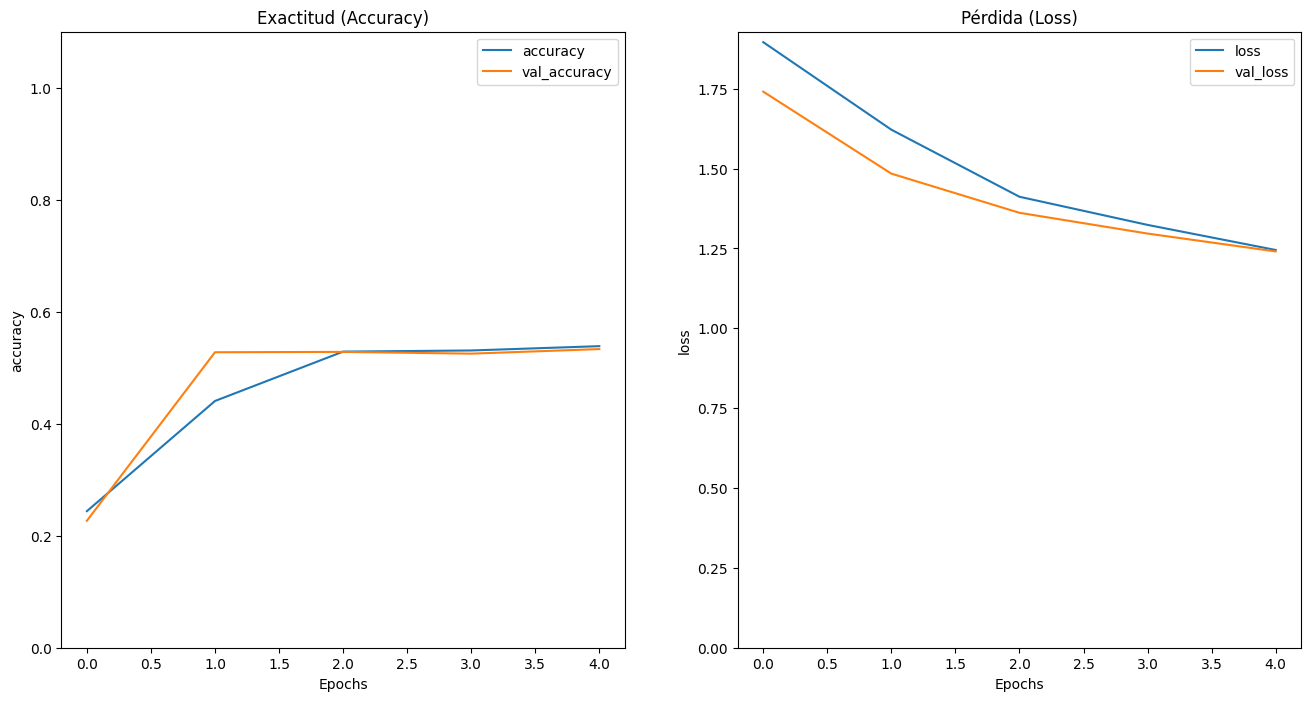

In [ ]:
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plot_graphs(history, 'accuracy')
plt.ylim(0, 1.1)
plt.title('Exactitud (Accuracy)')

plt.subplot(1, 2, 2)
plot_graphs(history, 'loss')
plt.ylim(0, None)
plt.title('Pérdida (Loss)')

plt.show()

### Conclusiones

**El modelo efectivamente está aprendiendo**: Tenemos 7 categorías (clases) distintas en el dataset. Si el modelo adivinara al azar, su exactitud sería cercana al 14% (1 dividido entre 7). Lograr un 53% demuestra que está logrando identificar patrones reales en el texto.

**Estancamiento rápido**: La gráfica de Exactitud (Accuracy), la línea naranja (validación) sube y luego se aplana casi de inmediato después de la primera época. Esto nos indica que el modelo rápidamente extrajo toda la información útil que pudo de los datos de entrenamiento disponibles.

**Falta de datos**: Como tomamos la decisión de reducir el dataset a solo un 15% para que el entrenamiento fuera más rápido, es normal que el modelo no pueda llegar a un 80% o 90% de exactitud; simplemente no ha visto suficientes ejemplos diferentes. Sin embargo, no vemos un problema grave de overfitting (donde la pérdida de validación empezaría a subir drásticamente).

### Paso 5: Automatización de Experimentos

In [ ]:
class RNNExperiment:
    def __init__(self, X_data, y_data, num_classes,
                 subset_fraction=0.15, vocab_size=5000,
                 embedding_dim=64, rnn_units=64,
                 epochs=5, batch_size=64):
        # Datos
        self.X = X_data
        self.y = y_data
        self.num_classes = num_classes

        # Hiperparámetros
        self.subset_fraction = subset_fraction
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.rnn_units = rnn_units
        self.epochs = epochs
        self.batch_size = batch_size

        # Variables internas
        self.model = None
        self.history = None

    def run(self, plot=True):
        print("="*50)
        print(f"INICIANDO EXPERIMENTO")
        print(f"Datos: {self.subset_fraction*100}% | Vocab: {self.vocab_size} | Embed: {self.embedding_dim} | RNN: {self.rnn_units}")
        print("="*50)

        # 1. Preparar Datos
        if self.subset_fraction < 1.0:
            X_sub, _, y_sub, _ = train_test_split(
                self.X, self.y, train_size=self.subset_fraction,
                random_state=42, stratify=self.y
            )
        else:
            X_sub, y_sub = self.X, self.y

        X_train, X_test, y_train, y_test = train_test_split(
            X_sub, y_sub, test_size=0.2, random_state=42, stratify=y_sub
        )

        print(f"Entrenando con {len(X_train)} muestras y probando con {len(X_test)}...")

        # 2. Configurar Vectorizador
        encoder = tf.keras.layers.TextVectorization(max_tokens=self.vocab_size)
        encoder.adapt(X_train)

        # 3. Construir Modelo
        self.model = tf.keras.Sequential([
            encoder,
            tf.keras.layers.Embedding(
                input_dim=len(encoder.get_vocabulary()),
                output_dim=self.embedding_dim,
                mask_zero=True
            ),
            tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(self.rnn_units, use_cudnn=False)),
            tf.keras.layers.Dense(self.rnn_units, activation='relu'),
            tf.keras.layers.Dense(self.num_classes, activation='softmax')
        ])

        self.model.compile(
            loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
            optimizer=tf.keras.optimizers.Adam(1e-4),
            metrics=['accuracy']
        )

        # 4. Entrenar
        print("Entrenando modelo...")
        self.history = self.model.fit(
            X_train, y_train,
            epochs=self.epochs,
            batch_size=self.batch_size,
            validation_data=(X_test, y_test),
            verbose=1
        )

        # 5. Evaluar
        print("Evaluando modelo...")
        test_loss, test_acc = self.model.evaluate(X_test, y_test, verbose=0)
        print(f"RESULTADO FINAL -> Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f}")

        # 6. Graficar
        if plot:
            self.plot_metrics()

        return test_acc

    def plot_metrics(self):
        plt.figure(figsize=(14, 5))
        # Exactitud
        plt.subplot(1, 2, 1)
        plt.plot(self.history.history['accuracy'], label='Train Accuracy')
        plt.plot(self.history.history['val_accuracy'], label='Val Accuracy')
        plt.title('Evolución de la Exactitud')
        plt.xlabel('Épocas')
        plt.ylabel('Accuracy')
        plt.legend()

        # Pérdida
        plt.subplot(1, 2, 2)
        plt.plot(self.history.history['loss'], label='Train Loss')
        plt.plot(self.history.history['val_loss'], label='Val Loss')
        plt.title('Evolución de la Pérdida')
        plt.xlabel('Épocas')
        plt.ylabel('Loss')
        plt.legend()

        plt.show()

### Modelo 2
Vamos a usar un **15% de los datos**, aumentar el **vocabulario a 8000**, pero reducir las dimensiones del **Embedding y RNN a 32** para ver si logramos un modelo más liviano pero igual de efectivo.

⚙️ INICIANDO EXPERIMENTO ⚙️
Datos: 15.0% | Vocab: 8000 | Embed: 32 | RNN: 32

1️⃣ Entrenando con 6364 muestras y probando con 1592...

2️⃣ Entrenando modelo...
Epoch 1/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 74s 727ms/step - accuracy: 0.2164 - loss: 1.9151 - val_accuracy: 0.2029 - val_loss: 1.8568
Epoch 2/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 73s 729ms/step - accuracy: 0.2522 - loss: 1.7334 - val_accuracy: 0.3122 - val_loss: 1.6846
Epoch 3/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 71s 717ms/step - accuracy: 0.4046 - loss: 1.6528 - val_accuracy: 0.4931 - val_loss: 1.6153
Epoch 4/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 73s 732ms/step - accuracy: 0.5264 - loss: 1.5569 - val_accuracy: 0.5289 - val_loss: 1.4781
Epoch 5/5
100/100 ━━━━━━━━━━━━━━━━━━━━ 72s 726ms/step - accuracy: 0.5283 - loss: 1.4137 - val_accuracy: 0.5270 - val_loss: 1.3657

3️⃣ Evaluando modelo...

🎯 RESULTADO FINAL -> Test Loss: 1.3657 | Test Accuracy: 0.5270


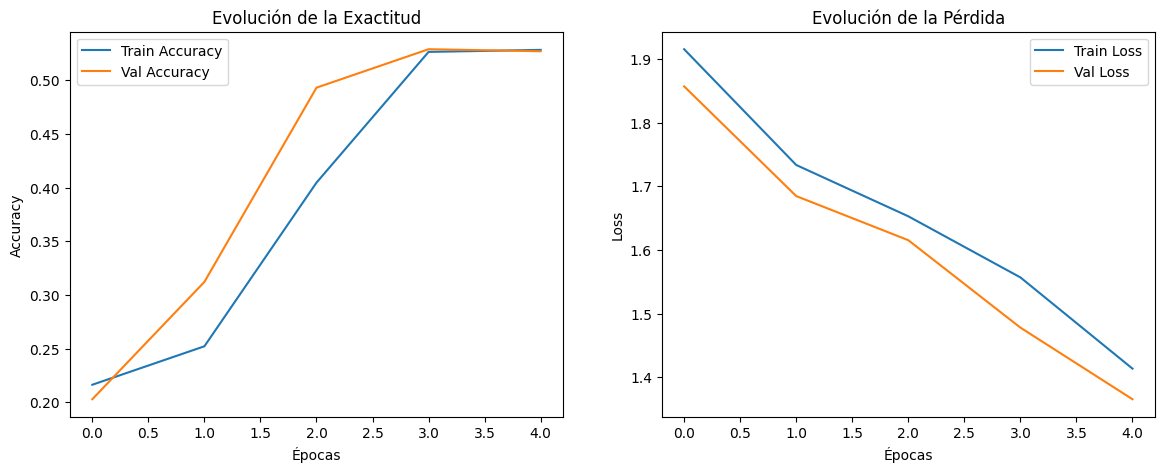

In [ ]:
modelo_2 = RNNExperiment(
    X_data=X,
    y_data=y_encoded,
    num_classes=num_classes,
    subset_fraction=0.15,  # 15% de los datos
    vocab_size=8000,       # Vocabulario más grande
    embedding_dim=32,      # Menos dimensiones
    rnn_units=32,          # Menos neuronas
    epochs=5,
    batch_size=64
)

acc_2 = modelo_2.run()

### Análisis del Modelo 2
* Reducir la complejidad de las capas (de 64 a 32) mantuvo el rendimiento casi intacto (~52.7% vs ~53.3%).
* Un modelo más ligero es suficiente para extraer los patrones de este subconjunto de datos.

### Modelo 3: Mayor Complejidad
Ahora probaremos una red más grande. Aumentaremos `embedding_dim` y `rnn_units` a **128** y reduciremos el `batch_size` a **32** para que el modelo actualice sus pesos más seguido.

⚙️ INICIANDO EXPERIMENTO ⚙️
Datos: 15.0% | Vocab: 5000 | Embed: 128 | RNN: 128

1️⃣ Entrenando con 6364 muestras y probando con 1592...

2️⃣ Entrenando modelo...
Epoch 1/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 114s 567ms/step - accuracy: 0.4507 - loss: 1.6620 - val_accuracy: 0.5276 - val_loss: 1.3888
Epoch 2/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 109s 549ms/step - accuracy: 0.5321 - loss: 1.3259 - val_accuracy: 0.5289 - val_loss: 1.2657
Epoch 3/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 111s 559ms/step - accuracy: 0.5399 - loss: 1.2130 - val_accuracy: 0.5427 - val_loss: 1.2081
Epoch 4/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 111s 558ms/step - accuracy: 0.5644 - loss: 1.1193 - val_accuracy: 0.5710 - val_loss: 1.1119
Epoch 5/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 110s 555ms/step - accuracy: 0.5907 - loss: 1.0253 - val_accuracy: 0.5798 - val_loss: 1.0663

3️⃣ Evaluando modelo...

🎯 RESULTADO FINAL -> Test Loss: 1.0663 | Test Accuracy: 0.5798


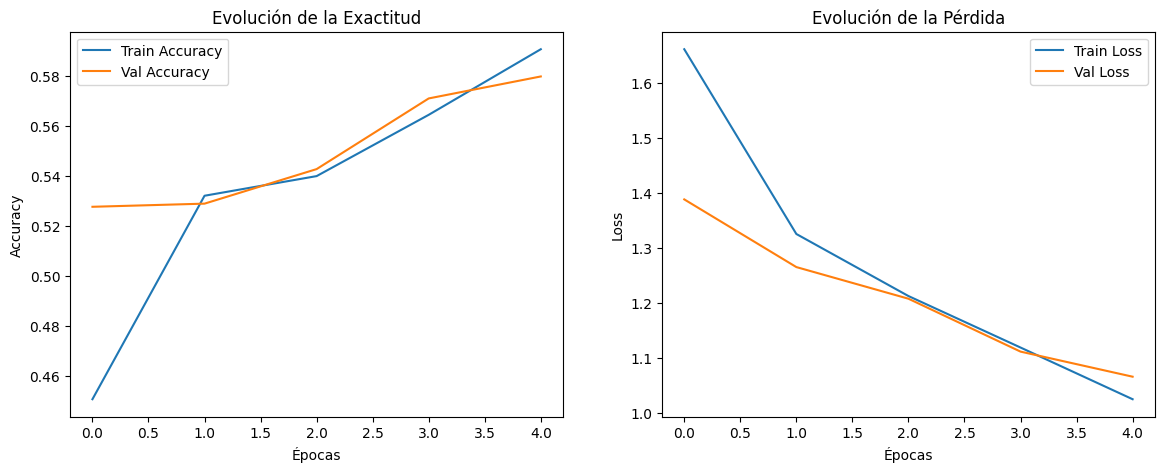

In [ ]:
modelo_3 = RNNExperiment(
    X_data=X,
    y_data=y_encoded,
    num_classes=num_classes,
    subset_fraction=0.15,
    vocab_size=5000,       # Volvemos al vocabulario original
    embedding_dim=128,     # Aumentamos dimensiones
    rnn_units=128,         # Aumentamos neuronas
    epochs=5,
    batch_size=32          # Lotes más pequeños
)

acc_3 = modelo_3.run()

### Análisis del Modelo 3
* Aumentar la complejidad arquitectónica (128 en Embedding y RNN) y reducir el `batch_size` mejoró notablemente el modelo, alcanzando un **58% de exactitud**.
* La pérdida sigue bajando consistentemente, demostrando que la red tiene mayor capacidad para entender los patrones.

### Modelo 4: El impacto de más datos
En lugar de seguir aumentando neuronas, vamos a darle al modelo más ejemplos de donde aprender. Aumentaremos el `subset_fraction` al **30%** del dataset total, pero mantendremos una arquitectura moderada (64 neuronas/dimensiones) para ver el efecto aislado del volumen de datos.

INICIANDO EXPERIMENTO
Datos: 30.0% | Vocab: 5000 | Embed: 64 | RNN: 64
Entrenando con 12729 muestras y probando con 3183...
Entrenando modelo...
Epoch 1/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 141s 702ms/step - accuracy: 0.4527 - loss: 1.7293 - val_accuracy: 0.5234 - val_loss: 1.4445
Epoch 2/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 140s 704ms/step - accuracy: 0.5311 - loss: 1.3702 - val_accuracy: 0.5256 - val_loss: 1.3404
Epoch 3/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 139s 689ms/step - accuracy: 0.5344 - loss: 1.3088 - val_accuracy: 0.5300 - val_loss: 1.2994
Epoch 4/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 142s 714ms/step - accuracy: 0.5438 - loss: 1.2300 - val_accuracy: 0.5407 - val_loss: 1.2068
Epoch 5/5
199/199 ━━━━━━━━━━━━━━━━━━━━ 141s 710ms/step - accuracy: 0.5596 - loss: 1.1450 - val_accuracy: 0.5595 - val_loss: 1.1387
Evaluando modelo...
RESULTADO FINAL -> Test Loss: 1.1387 | Test Accuracy: 0.5595


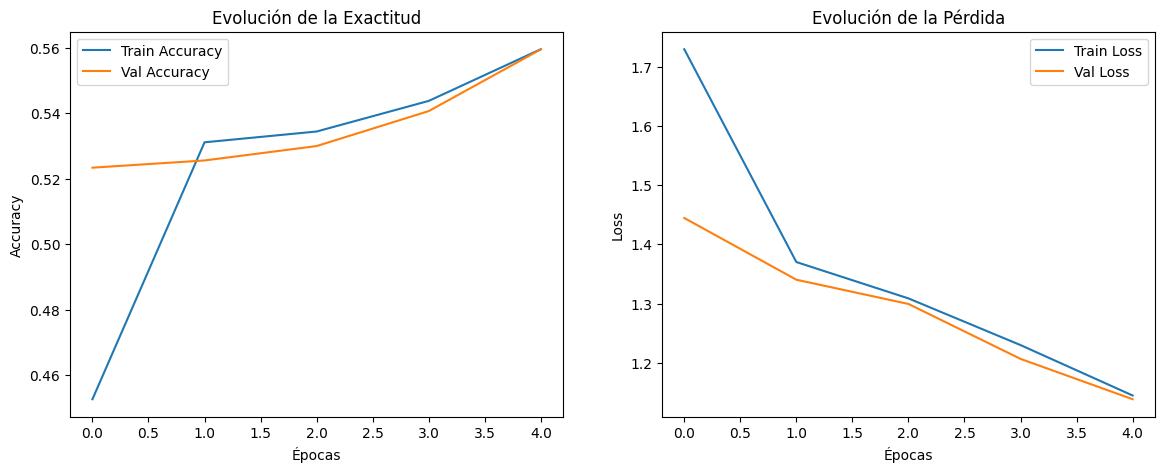

In [ ]:
modelo_4 = RNNExperiment(
    X_data=X,
    y_data=y_encoded,
    num_classes=num_classes,
    subset_fraction=0.30,  # Aumentamos los datos al 30%
    vocab_size=5000,       # Vocabulario estándar
    embedding_dim=64,      # Dimensiones moderadas
    rnn_units=64,          # Neuronas moderadas
    epochs=5,
    batch_size=64          # Lote estándar
)

acc_4 = modelo_4.run()

### Análisis del Modelo 4
* Doblar la cantidad de datos (del 15% al 30%) mejoró la exactitud de la arquitectura base de ~53% a casi **56%**.
* Sin embargo, no superó al Modelo 3 (58%). Esto nos indica que la arquitectura de 64 neuronas se satura, y para aprovechar más datos necesitamos una red más profunda/compleja.

### Modelo 5: Combinando lo mejor (El modelo definitivo)
Para nuestro quinto y último modelo comparativo del taller, vamos a juntar las mejores estrategias:
* **30% de los datos** (Mayor volumen de aprendizaje).
* **Vocabulario de 8000** (Para que reconozca más palabras).
* **128 dimensiones y neuronas** (Mayor capacidad de análisis).
* **Batch de 32** (Actualizaciones de pesos más constantes).

INICIANDO EXPERIMENTO
Datos: 30.0% | Vocab: 8000 | Embed: 128 | RNN: 128
Entrenando con 12729 muestras y probando con 3183...
Entrenando modelo...
Epoch 1/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 217s 542ms/step - accuracy: 0.4935 - loss: 1.5077 - val_accuracy: 0.5262 - val_loss: 1.3134
Epoch 2/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 217s 544ms/step - accuracy: 0.5474 - loss: 1.2011 - val_accuracy: 0.5608 - val_loss: 1.1313
Epoch 3/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 216s 543ms/step - accuracy: 0.5942 - loss: 1.0377 - val_accuracy: 0.5925 - val_loss: 1.0381
Epoch 4/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 216s 543ms/step - accuracy: 0.6352 - loss: 0.9252 - val_accuracy: 0.6073 - val_loss: 0.9956
Epoch 5/5
398/398 ━━━━━━━━━━━━━━━━━━━━ 217s 546ms/step - accuracy: 0.6775 - loss: 0.8223 - val_accuracy: 0.6092 - val_loss: 1.0066
Evaluando modelo...
RESULTADO FINAL -> Test Loss: 1.0066 | Test Accuracy: 0.6092


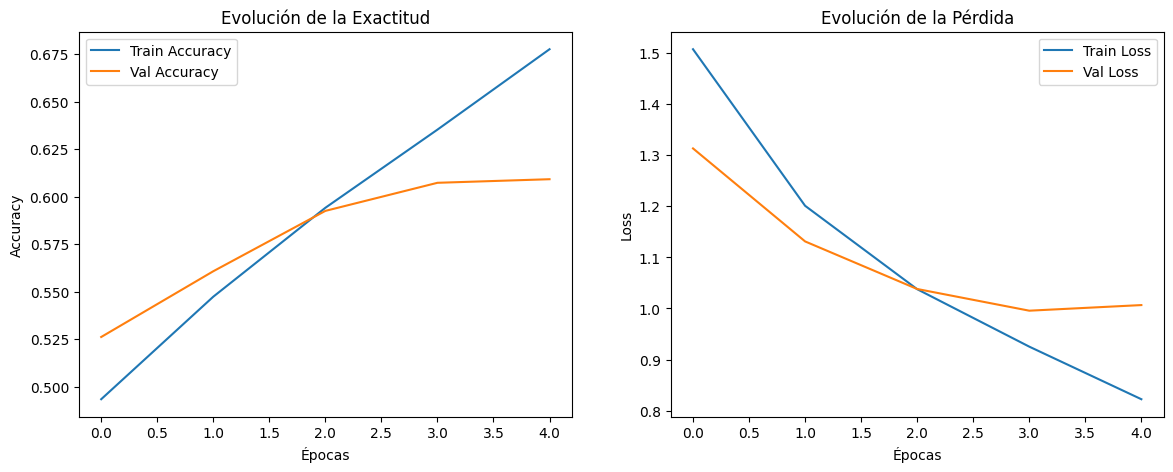

In [ ]:
modelo_5 = RNNExperiment(
    X_data=X,
    y_data=y_encoded,
    num_classes=num_classes,
    subset_fraction=0.30,  # 30% de los datos
    vocab_size=8000,       # Vocabulario ampliado
    embedding_dim=128,     # Alta capacidad
    rnn_units=128,         # Alta capacidad
    epochs=5,
    batch_size=32          # Lotes pequeños
)

acc_5 = modelo_5.run()

### Análisis del Modelo 5
* **El mejor rendimiento:** Al combinar un mayor volumen de datos (30%) con una arquitectura profunda (128 neuronas) y lotes pequeños, logramos romper la barrera del 60%, llegando a **~60.9%** en validación.
* **Señal de Alerta (Overfitting):** Aunque el modelo sigue mejorando en los datos de entrenamiento (llegando a casi 68% de exactitud), en la época 5 la pérdida de validación dejó de bajar y tuvo un ligero repunte. Esto indica que la red está empezando a memorizar los datos.

### Modelo Bonus 100% datos

INICIANDO EXPERIMENTO
Datos: 100.0% | Vocab: 12000 | Embed: 128 | RNN: 128
Entrenando con 42434 muestras y probando con 10609...
Entrenando modelo...
Epoch 1/5
1327/1327 ━━━━━━━━━━━━━━━━━━━━ 738s 555ms/step - accuracy: 0.5384 - loss: 1.2606 - val_accuracy: 0.5844 - val_loss: 1.0438
Epoch 2/5
1327/1327 ━━━━━━━━━━━━━━━━━━━━ 745s 561ms/step - accuracy: 0.6255 - loss: 0.9428 - val_accuracy: 0.6439 - val_loss: 0.9180
Epoch 3/5
1327/1327 ━━━━━━━━━━━━━━━━━━━━ 748s 564ms/step - accuracy: 0.6899 - loss: 0.8035 - val_accuracy: 0.6754 - val_loss: 0.8586
Epoch 4/5
1327/1327 ━━━━━━━━━━━━━━━━━━━━ 743s 560ms/step - accuracy: 0.7351 - loss: 0.7040 - val_accuracy: 0.6974 - val_loss: 0.8240
Epoch 5/5
1327/1327 ━━━━━━━━━━━━━━━━━━━━ 742s 560ms/step - accuracy: 0.7641 - loss: 0.6318 - val_accuracy: 0.7028 - val_loss: 0.8060
Evaluando modelo...
RESULTADO FINAL -> Test Loss: 0.8060 | Test Accuracy: 0.7028


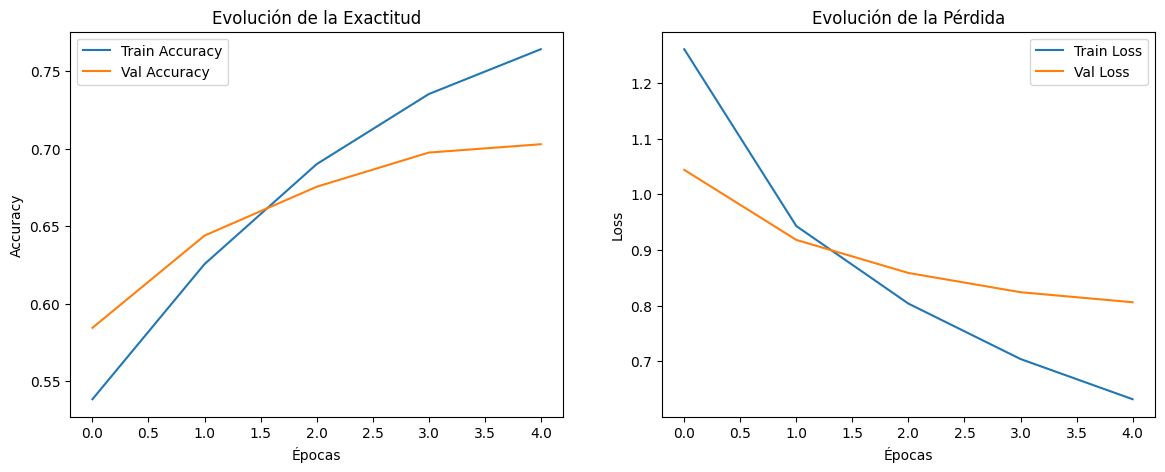

In [ ]:
modelo_bonus = RNNExperiment(
    X_data=X,
    y_data=y_encoded,
    num_classes=num_classes,
    subset_fraction=1.0,
    vocab_size=12000,
    embedding_dim=128,
    rnn_units=128,
    epochs=5,
    batch_size=32
)

acc_bonus = modelo_bonus.run()

## Conclusiones

Al ejecutar nuestro **Modelo Bonus**, le dimos a la red neuronal acceso al 100% del dataset y aumentamos su capacidad de lectura a un vocabulario de 12,000 palabras.

### Resultados Finales Comparativos:
1. **Modelo 1 (Base - 15% datos):** ~53.3% Exactitud
2. **Modelo 2 (Ligero - 15% datos):** ~52.7% Exactitud
3. **Modelo 3 (Profundo - 15% datos):** ~58.0% Exactitud
4. **Modelo 4 (Más Datos - 30% datos):** ~56.0% Exactitud
5. **Modelo 5 (Híbrido - 30% datos):** ~60.9% Exactitud
6. **Modelo Bonus (100% datos, red profunda):** **~70.3% Exactitud**

### Impacto de los Hiperparámetros Evaluados:
* **Dimensiones de Embedding y Neuronas LSTM (Capacidad de la red):**
  * Reducir las dimensiones de 64 a 32 (Modelo 2) con pocos datos apenas afectó la exactitud, demostrando que para pocos datos, una red pequeña basta.
  * Sin embargo, aumentar la capacidad a 128 (Modelos 3 y 5) demostró ser fundamental para romper el "techo" del 56% y acercarse o superar el 60%.
* **Tamaño del Lote (`batch_size`):** Bajar el tamaño del lote de 64 a 32 permitió que el modelo actualizara sus pesos con el doble de frecuencia en cada época. Esto demostró ser muy útil para ayudar a la red profunda (128 neuronas) a encontrar patrones más rápido (Modelo 3 y Modelo 5).
* **Tamaño del Vocabulario (`vocab_size`):** Expandir el vocabulario de 5,000 a 8,000 y finalmente a 12,000 demostró ser un cambio obligatorio a medida que aumentábamos la cantidad de datos. Más textos significan más palabras únicas que el modelo necesita "conocer" para no ignorarlas.

### Hallazgos Generales:
* **"Data is King" (Los datos mandan):** Modificar hiperparámetros de arquitectura nos permitió subir la exactitud de 53% a 61% (una mejora respetable). Sin embargo, darle al modelo el contexto completo (100% de los datos) nos dio un salto directo de casi 10 puntos adicionales, demostrando que en NLP, la cantidad de textos es el factor más crítico.
* **Mitigación del Overfitting:** En el Modelo 5 vimos que la red empezaba a sobreajustarse rápidamente porque tenía mucha capacidad (128 neuronas) pero pocos ejemplos (30% de datos). En el Modelo Bonus, al tener la misma capacidad pero muchos más ejemplos, la pérdida de validación continuó bajando de forma saludable.